In [1]:
%pip install -q -U ultralytics roboflow python-dotenv


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 131.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 10.7 MB/s eta 0:00:00


In [2]:
from roboflow import Roboflow
from dotenv import load_dotenv
import os
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# apikeys.env NO debe subirse a git ni compartirse: agrega la carpeta/archivo a .gitignore.
# Crea tu propio apikeys.env junto al notebook con una linea:
#   ROBOFLOW_API_KEY=tu_api_key_aqui
load_dotenv("apikeys.env")

api_key = os.getenv("ROBOFLOW_API_KEY")
if not api_key:
    try:
        from google.colab import userdata
        api_key = userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        api_key = None
if not api_key:
    raise RuntimeError(
        "No se encontro ROBOFLOW_API_KEY. Crea un archivo apikeys.env junto a este "
        "notebook con la linea: ROBOFLOW_API_KEY=tu_api_key_aqui"
    )

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
rf = Roboflow(api_key=api_key)
project = rf.workspace("roboflow-jvuqo").project("football-players-detection-3zvbc")
dataset = project.version(1).download("yolo26")

print(f"Dataset descargado en: {dataset.location}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to football-players-detection-1 in yolo26:: 100%|██████████| 1338/1338 [00:00<00:00, 3262.76it/s]


Dataset descargado en: /content/football-players-detection-1


In [4]:
# Load a model
model = YOLO("yolo26n.pt")  # load a pretrained model (recommended for training)

# Train the model
# Ruta portable: usamos dataset.location (definido en la celda anterior) en vez de
# una ruta absoluta especifica de una maquina/Studio, para que el notebook funcione
# en cualquier entorno donde se haya corrido la celda de descarga.
results = model.train(data=f"{dataset.location}/data.yaml", epochs=50)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/football-players-detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optim

In [5]:
import glob

# Ruta portable: tomamos la primera imagen del set de test que se descargo con Roboflow,
# en vez de una ruta absoluta especifica de una maquina/Studio.
test_images = sorted(glob.glob(f"{dataset.location}/test/images/*.jpg"))
assert test_images, f"No se encontraron imagenes de test en {dataset.location}/test/images"
image_path = test_images[0]
print(f"Usando imagen de prueba: {image_path}")

resultados = model(image_path, conf=0.25)

Usando imagen de prueba: /content/football-players-detection-1/test/images/40cd38_7_6_png.rf.68ef7fcd663cdf0f5b96bacdbcd94e07.jpg

image 1/1 /content/football-players-detection-1/test/images/40cd38_7_6_png.rf.68ef7fcd663cdf0f5b96bacdbcd94e07.jpg: 384x640 1 goalkeeper, 22 players, 1 referee, 11.7ms
Speed: 2.4ms preprocess, 11.7ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)


In [6]:
r = resultados[0] # r es un objeto de tipo 'ultralytics.yolo.engine.results.Results' que contiene toda la informacion de la inferencia

print("=== Informacion general ===")
print(f"Imagen original: {r.path}")
print(f"Tamano procesado: {r.orig_shape}")
print(f"Objetos detectados: {len(r.boxes)}")


print("\n=== Detecciones ===")
for i, box in enumerate(r.boxes):
    clase_id  = int(box.cls[0])
    clase_nom = model.names[clase_id]
    confianza = float(box.conf[0])
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    print(f"  [{i+1}] {clase_nom:15s} | confianza: {confianza:.2f} | bbox: ({x1:.0f},{y1:.0f}) → ({x2:.0f},{y2:.0f})")

=== Informacion general ===
Imagen original: /content/football-players-detection-1/test/images/40cd38_7_6_png.rf.68ef7fcd663cdf0f5b96bacdbcd94e07.jpg
Tamano procesado: (1080, 1920)
Objetos detectados: 24

=== Detecciones ===
  [1] player          | confianza: 0.89 | bbox: (1320,598) → (1354,658)
  [2] player          | confianza: 0.84 | bbox: (1857,754) → (1894,829)
  [3] player          | confianza: 0.84 | bbox: (545,671) → (595,747)
  [4] player          | confianza: 0.83 | bbox: (1746,675) → (1785,746)
  [5] player          | confianza: 0.83 | bbox: (1280,541) → (1299,588)
  [6] player          | confianza: 0.83 | bbox: (1081,788) → (1119,871)
  [7] player          | confianza: 0.83 | bbox: (1819,626) → (1847,690)
  [8] player          | confianza: 0.83 | bbox: (1685,613) → (1719,679)
  [9] player          | confianza: 0.83 | bbox: (814,480) → (839,523)
  [10] player          | confianza: 0.81 | bbox: (644,545) → (665,594)
  [11] player          | confianza: 0.80 | bbox: (763,478) →

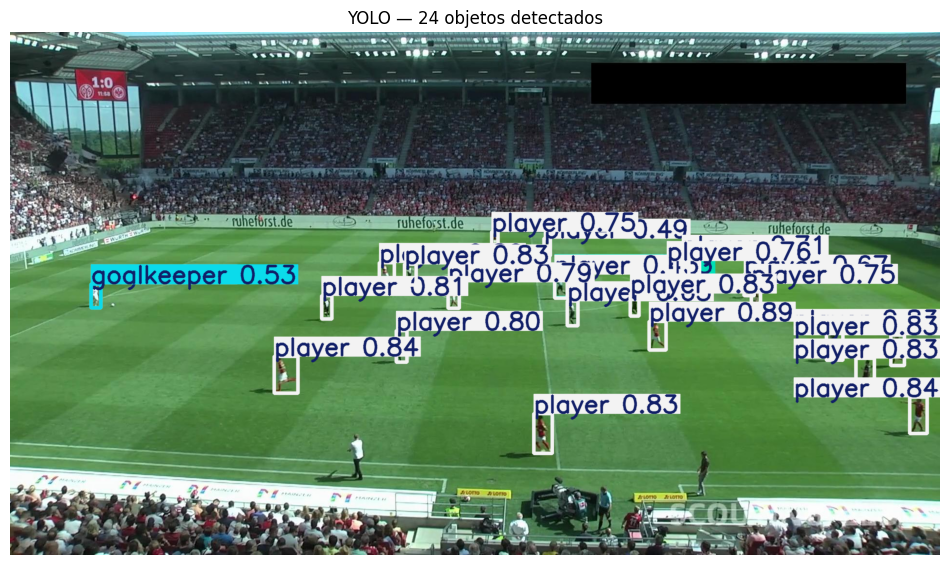

In [7]:

# r.plot() retorna la imagen anotada como array NumPy (BGR → convertir a RGB para matplotlib)
imagen_anotada = r.plot()
imagen_anotada_rgb = imagen_anotada[:, :, ::-1]  # BGR a RGB

plt.figure(figsize=(12, 7))
plt.imshow(imagen_anotada_rgb)
plt.title(f"YOLO — {len(r.boxes)} objetos detectados")
plt.axis("off")
plt.show()

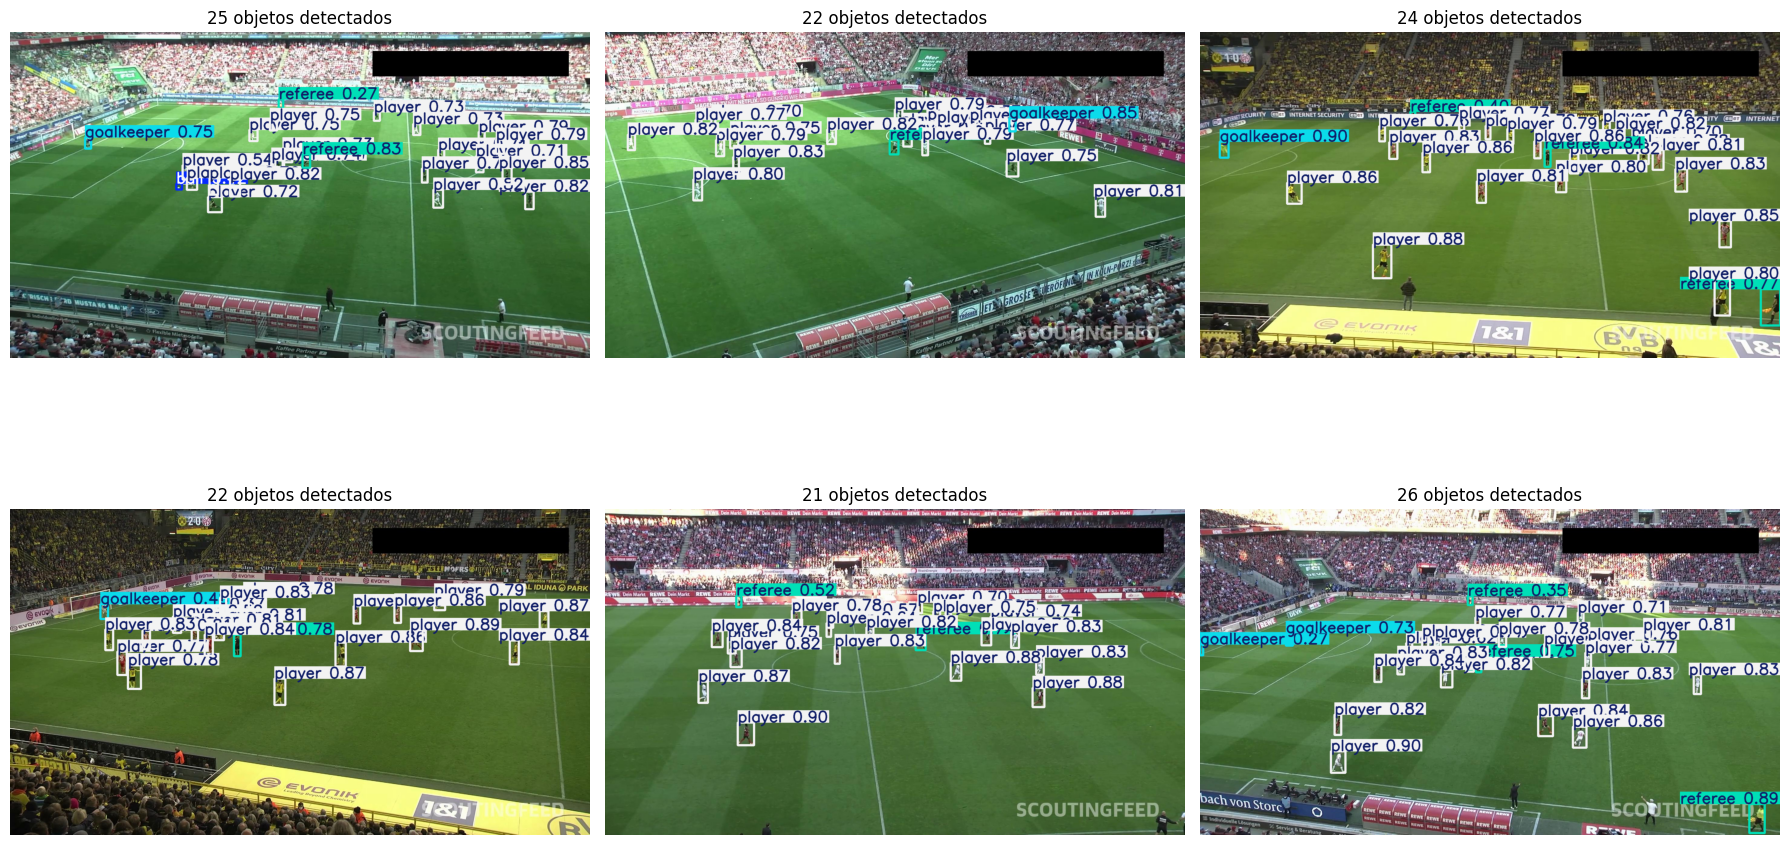

In [8]:
# Inferencia sobre varias imagenes del set de test (que el modelo no vio al entrenar)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, path in zip(axes.ravel(), test_images[1:7]):
    r_i = model(path, conf=0.25, verbose=False)[0]
    ax.imshow(r_i.plot()[:, :, ::-1])  # BGR a RGB
    ax.set_title(f"{len(r_i.boxes)} objetos detectados")
    ax.axis("off")
plt.tight_layout()
plt.show()